# Sleep Efficiency Linear Regression — v2

Revision of `Baseline.ipynb`. Changes:

| # | Change | Why |
|---|---|---|
| 1 | Hyper-parameters (alpha, l1_ratio, k) are tuned with **10-fold CV on the training set only**; the test set is used **once**, at the end | Selecting alpha by test RMSE (v1) leaks the test set into model selection |
| 2 | Notebook runs top-to-bottom (`Restart & Run All`) | v1 failed in the EDA and preprocessing cells |
| 3 | Bedtime → **hours from midnight** (21:30 → −2.5, 01:00 → +1). Wake-up time dropped | A Unix timestamp encodes the *date*, not the clock time. Wake-up = Bedtime + Sleep duration exactly (all 452 rows), so it is redundant |
| 4 | **REM / Deep / Light sleep % removed from all models** | Team decision; they are also perfectly collinear (sum = 100) |
| 5 | Finer alpha grid (`logspace(-4, 0)`), tuning curves plotted | In v1 every alpha ≥ 0.1 zeroed all coefficients |
| 6 | Baselines added: Trivial (mean), Simple (1-feature OLS), Strong (Random Forest, Gradient Boosting) | Required by §6.2 |
| 7 | Feature-engineering ablation (Set A / B / C) + paired t-test across folds | Required by §7 |
| 8 | Standardised OLS coefficients with 95% CI, p-value and VIF; error analysis | Required by §8 |

**Leakage rules kept from v1:** imputation and scaling are fitted inside the pipeline, i.e. on training folds only. Engineered features are computed **after** imputation, inside the pipeline.

## 1. Imports

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Configuration and dataset overview

In [2]:
SEED = 20261010
TEST_SIZE = 0.30
N_FOLDS = 10                    # ~32 validation rows per fold on 316 training rows
IMPUTATION_MODE = "mean_mode"   # "mean_mode" or "drop"
DATA_PATH = Path("Sleep_Efficiency.csv")
EDA_DIR = Path("eda_plots")
OUT_DIR = Path("results")
TARGET = "Sleep efficiency"

sns.set_theme(style="whitegrid", context="notebook")
EDA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
for col in df_raw.columns:
    if df_raw[col].dtype == object or pd.api.types.is_string_dtype(df_raw[col]):
        df_raw[col] = df_raw[col].map(lambda x: x.strip() if isinstance(x, str) else x)

print(f"Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(df_raw.head().to_string())

Shape: 452 rows x 15 columns
   ID  Age  Gender              Bedtime          Wakeup time  Sleep duration  Sleep efficiency  REM sleep percentage  Deep sleep percentage  Light sleep percentage  Awakenings  Caffeine consumption  Alcohol consumption Smoking status  Exercise frequency
0   1   65  Female  2021-03-06 01:00:00  2021-03-06 07:00:00             6.0              0.88                    18                     70                      12         0.0                   0.0                  0.0            Yes                 3.0
1   2   69    Male  2021-12-05 02:00:00  2021-12-05 09:00:00             7.0              0.66                    19                     28                      53         3.0                   0.0                  3.0            Yes                 3.0
2   3   40  Female  2021-05-25 21:30:00  2021-05-25 05:30:00             8.0              0.89                    20                     70                      10         1.0                   0.0            

## 3. Data quality

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
})
print(missing_summary.sort_values("missing_count", ascending=False).to_string())
print(f"\nExact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Duplicate IDs: {df_raw['ID'].duplicated().sum()}")

# Sanity checks that drive feature decisions
stage_sum = df_raw[["REM sleep percentage", "Deep sleep percentage", "Light sleep percentage"]].sum(axis=1)
print(f"\nREM + Deep + Light == 100 for {np.mean(stage_sum == 100):.0%} of rows")

bed = pd.to_datetime(df_raw["Bedtime"])
wake = pd.to_datetime(df_raw["Wakeup time"])
gap = (wake - bed).dt.total_seconds() / 3600
gap = np.where(gap < 0, gap + 24, gap)
print(f"Wake-up == Bedtime + Sleep duration for {np.mean(np.isclose(gap, df_raw['Sleep duration'])):.0%} of rows")

                        missing_count  missing_percent
Caffeine consumption               25             5.53
Awakenings                         20             4.42
Alcohol consumption                14             3.10
Exercise frequency                  6             1.33
ID                                  0             0.00
Age                                 0             0.00
Gender                              0             0.00
Sleep efficiency                    0             0.00
Sleep duration                      0             0.00
Wakeup time                         0             0.00
Bedtime                             0             0.00
Light sleep percentage              0             0.00
Deep sleep percentage               0             0.00
REM sleep percentage                0             0.00
Smoking status                      0             0.00

Exact duplicate rows: 0
Duplicate IDs: 0

REM + Deep + Light == 100 for 100% of rows
Wake-up == Bedtime + Sleep duratio

## 4. Preprocessing and train/test split

- `Gender`: Male = 0, Female = 1; `Smoking status`: No = 0, Yes = 1
- `Bedtime_h` = clock time in hours from midnight (evenings negative)
- Dropped: `ID`, `Bedtime` / `Wakeup time` (raw strings), the three sleep-stage percentages
- Split **before** any EDA statistics, so EDA below uses training rows only

In [4]:
df = df_raw.copy()
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Smoking status"] = df["Smoking status"].map({"No": 0, "Yes": 1})
hour = pd.to_datetime(df["Bedtime"]).dt.hour + pd.to_datetime(df["Bedtime"]).dt.minute / 60
df["Bedtime_h"] = np.where(hour >= 12, hour - 24, hour)

RAW_FEATURES = [
    "Age", "Gender", "Sleep duration", "Bedtime_h", "Awakenings",
    "Caffeine consumption", "Alcohol consumption", "Smoking status", "Exercise frequency",
]
BINARY = ["Gender", "Smoking status"]
NUMERIC = [c for c in RAW_FEATURES if c not in BINARY]
DROPPED = ["ID", "Bedtime", "Wakeup time",
           "REM sleep percentage", "Deep sleep percentage", "Light sleep percentage"]
print("Dropped columns:", DROPPED)

if IMPUTATION_MODE == "drop":
    before = len(df)
    df = df.dropna(subset=RAW_FEATURES + [TARGET])
    print(f"Drop mode: removed {before - len(df)} rows with missing values")
elif IMPUTATION_MODE != "mean_mode":
    raise ValueError("IMPUTATION_MODE must be 'mean_mode' or 'drop'")

X = df[RAW_FEATURES]
y = df[TARGET].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, shuffle=True)
print(f"Train rows: {len(X_train)}   Test rows: {len(X_test)}")

# One fixed fold assignment shared by every model (same folds -> paired comparisons)
CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

Dropped columns: ['ID', 'Bedtime', 'Wakeup time', 'REM sleep percentage', 'Deep sleep percentage', 'Light sleep percentage']
Train rows: 316   Test rows: 136


## 5. EDA (training set only)

Mean efficiency by smoking x heavy drinking (train):
                              mean  size
Smoking status                          
Non-smoker     Alcohol 0-1   0.829   153
               Alcohol >= 2  0.791    56
Smoker         Alcohol 0-1   0.797    68
               Alcohol >= 2  0.600    39


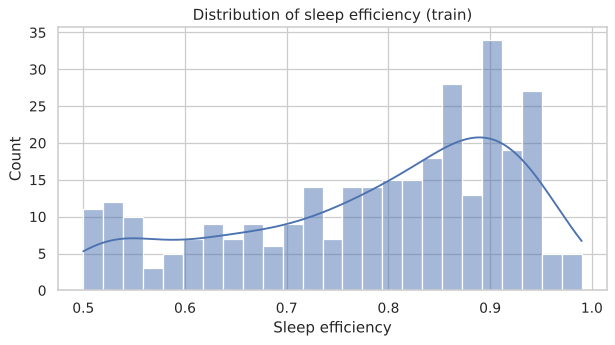

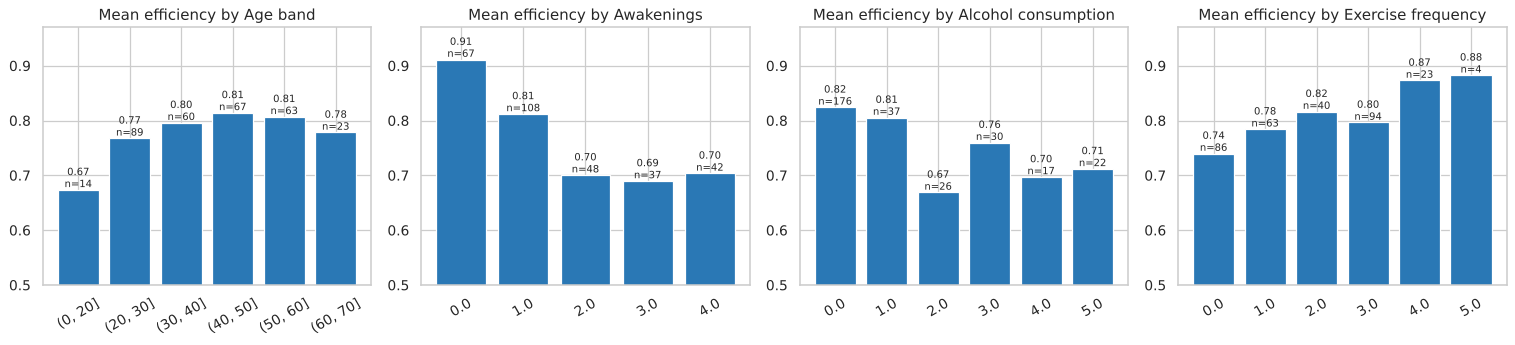

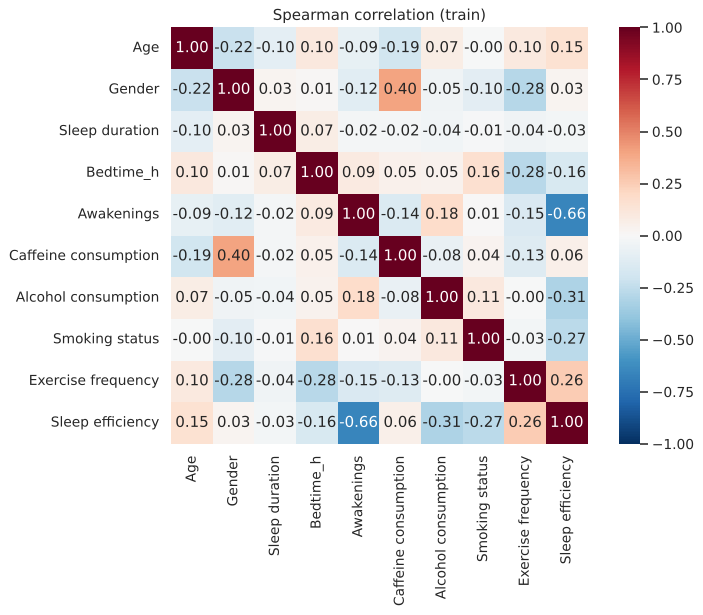

In [5]:
eda = X_train.assign(**{TARGET: y_train})

# Target distribution
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(eda[TARGET], bins=25, kde=True, ax=ax)
ax.set_title("Distribution of sleep efficiency (train)")
fig.tight_layout(); fig.savefig(EDA_DIR / "01_target_distribution.png", dpi=160); plt.show()

# Mean efficiency by the levels used for feature engineering
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
age_bins = pd.cut(eda["Age"], [0, 20, 30, 40, 50, 60, 70])
for ax, (name, key) in zip(axes, [
        ("Age band", age_bins),
        ("Awakenings", eda["Awakenings"]),
        ("Alcohol consumption", eda["Alcohol consumption"]),
        ("Exercise frequency", eda["Exercise frequency"])]):
    g = eda.groupby(key, observed=True)[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color="#2a78b5")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.005, f"{m:.2f}\nn={n}", ha="center", fontsize=8)
    ax.set_ylim(0.5, 0.97); ax.set_title(f"Mean efficiency by {name}")
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(EDA_DIR / "02_levels_vs_target.png", dpi=160); plt.show()

# Smoking x heavy drinking (motivates the interaction feature)
tab = eda.groupby([eda["Smoking status"].map({0: "Non-smoker", 1: "Smoker"}),
                   np.where(eda["Alcohol consumption"] >= 2, "Alcohol >= 2", "Alcohol 0-1")])[TARGET] \
         .agg(["mean", "size"]).round(3)
print("Mean efficiency by smoking x heavy drinking (train):")
print(tab.to_string())

# Correlation heatmap (Spearman, pairwise complete)
corr = eda.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Spearman correlation (train)")
fig.tight_layout(); fig.savefig(EDA_DIR / "03_correlation_heatmap.png", dpi=160); plt.show()

## 6. Feature engineering

Each engineered feature is tied to an EDA observation (training data):

| Feature | Definition | EDA evidence |
|---|---|---|
| `Awak_cap2` | `min(Awakenings, 2)` — replaces `Awakenings` | Efficiency drops from 0 → 1 → 2 awakenings, then is flat (≈0.70 for 2, 3, 4) |
| `Age_sq` | `(Age − 40)²` | Inverted-U: lowest for < 20 and ≥ 60, highest for 40–50 |
| `Alc_heavy` | `1[Alcohol ≥ 2]` | 0–1 drinks barely matter; ≥ 2 drinks is a clear step down |
| `Ex_any` | `1[Exercise ≥ 1]` | Largest gain is from 0 to any exercise |
| `Smk_x_AlcHeavy` | `Smoking × Alc_heavy` | Smokers who drink ≥ 2: 0.60 vs ≈ 0.79–0.83 for the other three groups |

Features are built **after** imputation inside the pipeline, so each training fold only sees its own statistics.

                             Step  n_features  CV_MAE_mean  CV_MAE_std
                       Set A: raw           9       0.0808      0.0093
+ Awak_cap2 (replaces Awakenings)           9       0.0780      0.0075
                         + Age_sq          10       0.0772      0.0069
                      + Alc_heavy          11       0.0755      0.0081
                         + Ex_any          12       0.0743      0.0082
                 + Smk_x_AlcHeavy          13       0.0692      0.0101


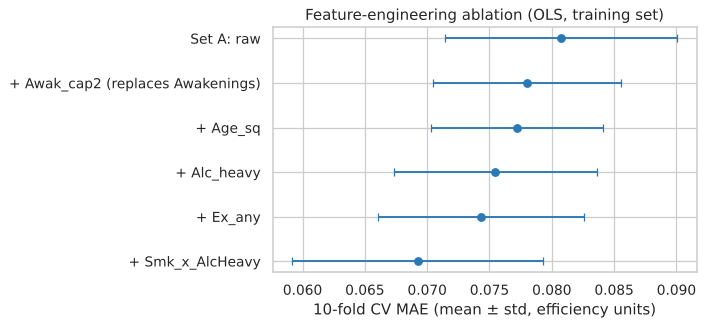

In [6]:
ENGINEERED = ["Awak_cap2", "Age_sq", "Alc_heavy", "Ex_any", "Smk_x_AlcHeavy"]

def add_features(Xdf, keep):
    # Build engineered columns from the (already imputed) raw columns, return `keep` columns.
    X = Xdf.copy()
    X["Awak_cap2"] = X["Awakenings"].clip(upper=2)
    X["Age_sq"] = (X["Age"] - 40) ** 2
    X["Alc_heavy"] = (X["Alcohol consumption"] >= 2).astype(float)
    X["Ex_any"] = (X["Exercise frequency"] >= 1).astype(float)
    X["Smk_x_AlcHeavy"] = X["Smoking status"] * X["Alc_heavy"]
    return X[keep]

def make_pipeline(features, model, select_k=None, scale=True):
    # impute raw columns -> engineer -> (optional in-fold top-k selection) -> scale -> model
    imputer = ColumnTransformer(
        [("num", SimpleImputer(strategy="mean"), NUMERIC),
         ("bin", SimpleImputer(strategy="most_frequent"), BINARY)],
        verbose_feature_names_out=False).set_output(transform="pandas")
    steps = [("impute", imputer),
             ("features", FunctionTransformer(add_features, kw_args={"keep": list(features)}))]
    if select_k is not None:
        steps.append(("select", SelectKBest(f_regression, k=select_k)))
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

SET_A = RAW_FEATURES                                                      # all raw columns
SET_C = [c for c in RAW_FEATURES if c != "Awakenings"] + ENGINEERED       # raw + engineered

def cv_mae(pipe, Xd=X_train, yd=y_train):
    s = -cross_val_score(pipe, Xd, yd, cv=CV, scoring="neg_mean_absolute_error")
    return s

# Ablation ladder: add one engineered feature at a time (OLS, same folds)
ladder = [("Set A: raw", SET_A)]
cur = [c for c in RAW_FEATURES if c != "Awakenings"] + ["Awak_cap2"]
ladder.append(("+ Awak_cap2 (replaces Awakenings)", list(cur)))
for f in ["Age_sq", "Alc_heavy", "Ex_any", "Smk_x_AlcHeavy"]:
    cur = cur + [f]
    ladder.append((f"+ {f}", list(cur)))

rows = []
for name, feats in ladder:
    s = cv_mae(make_pipeline(feats, LinearRegression()))
    rows.append({"Step": name, "n_features": len(feats), "CV_MAE_mean": s.mean(), "CV_MAE_std": s.std()})
ladder_df = pd.DataFrame(rows)
print(ladder_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
ladder_df.to_csv(OUT_DIR / "fe_ablation_ladder.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(ladder_df["CV_MAE_mean"], range(len(ladder_df)), xerr=ladder_df["CV_MAE_std"],
            fmt="o", color="#2a78b5", capsize=3)
ax.set_yticks(range(len(ladder_df)), ladder_df["Step"]); ax.invert_yaxis()
ax.set_xlabel(f"{N_FOLDS}-fold CV MAE (mean ± std, efficiency units)")
ax.set_title("Feature-engineering ablation (OLS, training set)")
fig.tight_layout(); fig.savefig(OUT_DIR / "01_fe_ladder.png", dpi=160); plt.show()

## 7. Feature sets for the §7.2 ablation

- **Set A** — all raw columns (9)
- **Set B** — top-*k* raw columns by |correlation| with the target, selected **inside every training fold** (`SelectKBest` is a pipeline step); *k* tuned by CV
- **Set C** — raw + engineered (13)

In [7]:
gs_B = GridSearchCV(make_pipeline(SET_A, LinearRegression(), select_k=3),
                    {"select__k": list(range(1, len(SET_A) + 1))},
                    cv=CV, scoring="neg_mean_absolute_error").fit(X_train, y_train)
k_curve = pd.DataFrame({"k": gs_B.cv_results_["param_select__k"].astype(int),
                        "CV_MAE": -gs_B.cv_results_["mean_test_score"],
                        "std": gs_B.cv_results_["std_test_score"]})
print(k_curve.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
BEST_K = gs_B.best_params_["select__k"]
print(f"\nBest k = {BEST_K}")

# Which columns does the top-k step pick when fitted on the full training set?
sel = gs_B.best_estimator_.named_steps["select"]
picked = np.array(SET_A)[sel.get_support()]
print("Columns picked on the full training set:", [str(c) for c in picked])

 k  CV_MAE    std
 1  0.0905 0.0122
 2  0.0885 0.0113
 3  0.0824 0.0087
 4  0.0806 0.0086
 5  0.0802 0.0085
 6  0.0797 0.0089
 7  0.0800 0.0095
 8  0.0805 0.0094
 9  0.0808 0.0093

Best k = 6
Columns picked on the full training set: ['Age', 'Bedtime_h', 'Awakenings', 'Alcohol consumption', 'Smoking status', 'Exercise frequency']


## 8. Model selection on Set C (CV on training set only)

OLS, Ridge, LASSO, Elastic Net. Grids: alpha ∈ `logspace(-4, 0, 30)`; Elastic Net l1_ratio ∈ {0.1, 0.3, 0.5, 0.7, 0.9}.

      Model                         Best params  CV_MAE_mean  CV_MAE_std
        OLS                                  {}       0.0692      0.0101
      Ridge                 {'alpha': 13.73824}       0.0690      0.0097
      LASSO                  {'alpha': 0.00174}       0.0686      0.0090
Elastic Net {'alpha': 0.00174, 'l1_ratio': 0.9}       0.0686      0.0090

Selected final model (lowest CV MAE): Elastic Net


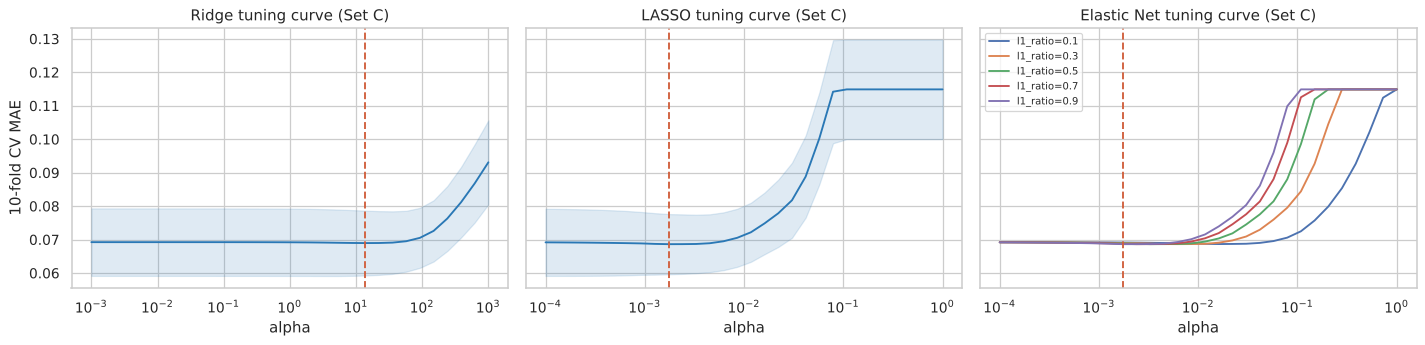

In [8]:
ALPHAS = np.logspace(-4, 0, 30)
searches = {
    "OLS": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 30)}),
    "LASSO": (Lasso(max_iter=100_000), {"model__alpha": ALPHAS}),
    "Elastic Net": (ElasticNet(max_iter=100_000), {"model__alpha": ALPHAS,
                                                   "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}

def fold_scores(gs):
    # Per-fold MAE of the best parameter setting (same CV folds for every model).
    i = gs.best_index_
    return np.array([-gs.cv_results_[f"split{f}_test_score"][i] for f in range(N_FOLDS)])

fitted, fold_mae, rows = {}, {}, []
for name, (est, grid) in searches.items():
    gs = GridSearchCV(make_pipeline(SET_C, est), grid or [{}], cv=CV,
                      scoring="neg_mean_absolute_error").fit(X_train, y_train)
    fitted[name] = gs
    fold_mae[name] = fold_scores(gs)
    rows.append({"Model": name, "Best params": {k.replace("model__", ""): round(float(v), 5)
                                                for k, v in gs.best_params_.items()},
                 "CV_MAE_mean": fold_mae[name].mean(), "CV_MAE_std": fold_mae[name].std()})
sel_df = pd.DataFrame(rows)
print(sel_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Tuning curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, ["Ridge", "LASSO", "Elastic Net"]):
    r = pd.DataFrame(fitted[name].cv_results_)
    if name == "Elastic Net":
        for l1 in sorted(r["param_model__l1_ratio"].unique()):
            s = r[r["param_model__l1_ratio"] == l1]
            ax.plot(s["param_model__alpha"].astype(float), -s["mean_test_score"], label=f"l1_ratio={l1}")
        ax.legend(fontsize=8)
    else:
        a = r["param_model__alpha"].astype(float); m = -r["mean_test_score"]; sd = r["std_test_score"]
        ax.plot(a, m, color="#2a78b5"); ax.fill_between(a, m - sd, m + sd, alpha=0.15, color="#2a78b5")
    ax.axvline(float(fitted[name].best_params_["model__alpha"]), ls="--", color="#d1603d")
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_title(f"{name} tuning curve (Set C)")
axes[0].set_ylabel(f"{N_FOLDS}-fold CV MAE")
fig.tight_layout(); fig.savefig(OUT_DIR / "02_tuning_curves.png", dpi=160); plt.show()

FINAL_NAME = sel_df.sort_values("CV_MAE_mean").iloc[0]["Model"]
print(f"\nSelected final model (lowest CV MAE): {FINAL_NAME}")

## 9. Baselines and Set A / B (same folds)

- **Trivial**: predict the training mean
- **Simple**: OLS on the single raw feature with the highest |correlation| with the target (chosen on the training set)
- **Strong**: Random Forest and Gradient Boosting on raw features (Set A)

In [9]:
corr_with_y = X_train.assign(y=y_train).corr(method="spearman")["y"].drop("y")
SIMPLE_FEATURE = corr_with_y.abs().idxmax()
print(f"Simple baseline feature: {SIMPLE_FEATURE} (Spearman rho = {corr_with_y[SIMPLE_FEATURE]:.2f})")

baselines = {
    "Trivial (mean)": make_pipeline(SET_A, DummyRegressor(strategy="mean")),
    f"Simple OLS ({SIMPLE_FEATURE})": make_pipeline([SIMPLE_FEATURE], LinearRegression()),
    "Set A: OLS (raw)": make_pipeline(SET_A, LinearRegression()),
    f"Set B: OLS (top-{BEST_K}, in-fold)": make_pipeline(SET_A, LinearRegression(), select_k=BEST_K),
    "Random Forest (raw)": make_pipeline(SET_A, RandomForestRegressor(
        n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1), scale=False),
    "Gradient Boosting (raw)": make_pipeline(SET_A, GradientBoostingRegressor(random_state=SEED), scale=False),
}
for name, pipe in baselines.items():
    fold_mae[name] = cv_mae(pipe)

final_label = f"Set C: {FINAL_NAME} (ours)"
fold_mae[final_label] = fold_mae[FINAL_NAME]

Simple baseline feature: Awakenings (Spearman rho = -0.66)


## 10. Final evaluation on the test set (used once)

In [10]:
def test_metrics(pipe):
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    return {"Test_MAE": mean_absolute_error(y_test, p),
            "Test_RMSE": np.sqrt(mean_squared_error(y_test, p)),
            "Test_R2": r2_score(y_test, p)}, p

final_pipe = fitted[FINAL_NAME].best_estimator_
all_models = {**baselines, final_label: final_pipe}
order = ["Trivial (mean)", f"Simple OLS ({SIMPLE_FEATURE})", "Set A: OLS (raw)",
         f"Set B: OLS (top-{BEST_K}, in-fold)", final_label,
         "Random Forest (raw)", "Gradient Boosting (raw)"]

rows, preds = [], {}
for name in order:
    m, p = test_metrics(all_models[name])
    preds[name] = p
    rows.append({"Model": name, "CV_MAE": fold_mae[name].mean(), "CV_MAE_std": fold_mae[name].std(), **m})
main_df = pd.DataFrame(rows)
print(main_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
main_df.to_csv(OUT_DIR / "main_results.csv", index=False)

                      Model  CV_MAE  CV_MAE_std  Test_MAE  Test_RMSE  Test_R2
             Trivial (mean)  0.1149      0.0149    0.1146     0.1336  -0.0017
    Simple OLS (Awakenings)  0.0905      0.0122    0.0901     0.1082   0.3431
           Set A: OLS (raw)  0.0808      0.0093    0.0739     0.0927   0.5177
Set B: OLS (top-6, in-fold)  0.0797      0.0089    0.0743     0.0932   0.5125
  Set C: Elastic Net (ours)  0.0686      0.0090    0.0630     0.0812   0.6301
        Random Forest (raw)  0.0611      0.0062    0.0591     0.0776   0.6617
    Gradient Boosting (raw)  0.0644      0.0092    0.0606     0.0791   0.6484


## 11. Significance tests (paired over the same CV folds)

Paired t-test on the 10 per-fold MAEs (plus Wilcoxon signed-rank as a non-parametric check).
A difference smaller than the fold-to-fold spread is **not** claimed as an improvement.

In [11]:
def paired(a, b):
    d = fold_mae[a] - fold_mae[b]
    t = stats.ttest_rel(fold_mae[a], fold_mae[b])
    w = stats.wilcoxon(fold_mae[a], fold_mae[b])
    return {"Comparison": f"{a}  vs  {b}", "Mean diff (MAE)": d.mean(), "Std diff": d.std(ddof=1),
            "t": t.statistic, "p (t-test)": t.pvalue, "p (Wilcoxon)": w.pvalue}

strongest = min(["Random Forest (raw)", "Gradient Boosting (raw)"], key=lambda n: fold_mae[n].mean())
sig_df = pd.DataFrame([
    paired(final_label, "Set A: OLS (raw)"),
    paired(final_label, f"Set B: OLS (top-{BEST_K}, in-fold)"),
    paired(final_label, strongest),
])
print(sig_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nNegative mean diff = our model has lower error.")
sig_df.to_csv(OUT_DIR / "significance_tests.csv", index=False)

                                                Comparison  Mean diff (MAE)  Std diff       t  p (t-test)  p (Wilcoxon)
           Set C: Elastic Net (ours)  vs  Set A: OLS (raw)          -0.0121    0.0051 -7.5474      0.0000        0.0020
Set C: Elastic Net (ours)  vs  Set B: OLS (top-6, in-fold)          -0.0111    0.0062 -5.6903      0.0003        0.0039
        Set C: Elastic Net (ours)  vs  Random Forest (raw)           0.0075    0.0071  3.3249      0.0089        0.0137

Negative mean diff = our model has lower error.


## 12. Coefficients: standardised β, 95% CI, p-value, VIF (OLS on Set C, training set)

Features are standardised, so β = change in sleep efficiency per **1 SD** of the feature.
Inference uses OLS t-tests even if a regularised model was selected for prediction
(for LASSO/Ridge, bootstrap CIs would be the matching choice).

Intercept = 0.7872   n = 316   residual df = 302
             Feature  beta (per SD)  CI_low  CI_high  p_value    VIF
           Awak_cap2        -0.0656 -0.0757  -0.0556   0.0000 1.1214
      Smk_x_AlcHeavy        -0.0421 -0.0566  -0.0276   0.0000 2.3300
           Alc_heavy        -0.0267 -0.0508  -0.0026   0.0300 6.4342
              Ex_any         0.0230  0.0064   0.0395   0.0067 3.0358
      Smoking status        -0.0214 -0.0336  -0.0092   0.0006 1.6489
                 Age         0.0193  0.0088   0.0297   0.0003 1.2087
              Age_sq        -0.0165 -0.0270  -0.0060   0.0021 1.2191
 Alcohol consumption         0.0136 -0.0087   0.0359   0.2321 5.5270
      Sleep duration        -0.0030 -0.0127   0.0067   0.5431 1.0461
              Gender        -0.0030 -0.0136   0.0077   0.5845 1.2579
Caffeine consumption        -0.0026 -0.0131   0.0080   0.6339 1.2297
           Bedtime_h        -0.0012 -0.0122   0.0097   0.8272 1.3321
  Exercise frequency         0.0001 -0.0171   0.0172  

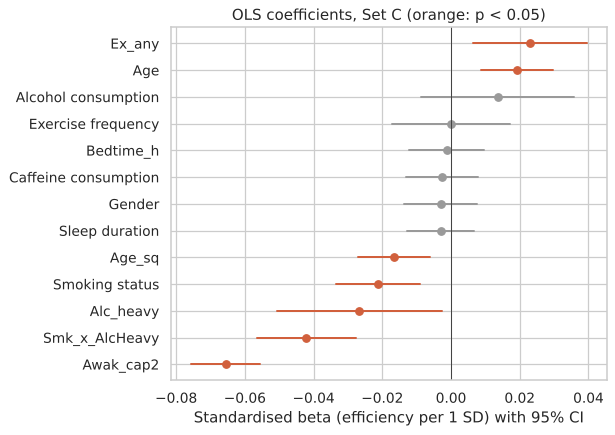

In [12]:
prep = make_pipeline(SET_C, LinearRegression())[:-1]          # impute -> features -> scale
Z = prep.fit_transform(X_train, y_train)
Zc = np.column_stack([np.ones(len(Z)), Z])
beta, *_ = np.linalg.lstsq(Zc, y_train.values, rcond=None)
resid = y_train.values - Zc @ beta
dof = len(y_train) - Zc.shape[1]
sigma2 = resid @ resid / dof
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Zc.T @ Zc)))
tval = beta / se
pval = 2 * stats.t.sf(np.abs(tval), dof)
tcrit = stats.t.ppf(0.975, dof)

def vif(M):
    out = []
    for j in range(M.shape[1]):
        others = np.column_stack([np.ones(len(M)), np.delete(M, j, axis=1)])
        b, *_ = np.linalg.lstsq(others, M[:, j], rcond=None)
        r2 = 1 - ((M[:, j] - others @ b) ** 2).sum() / ((M[:, j] - M[:, j].mean()) ** 2).sum()
        out.append(1 / (1 - r2))
    return out

coef_df = pd.DataFrame({
    "Feature": SET_C, "beta (per SD)": beta[1:], "CI_low": beta[1:] - tcrit * se[1:],
    "CI_high": beta[1:] + tcrit * se[1:], "p_value": pval[1:], "VIF": vif(Z),
}).sort_values("beta (per SD)", key=abs, ascending=False)
print(f"Intercept = {beta[0]:.4f}   n = {len(y_train)}   residual df = {dof}")
print(coef_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
coef_df.to_csv(OUT_DIR / "ols_coefficients_setC.csv", index=False)

# Coefficients of the selected (possibly regularised) model, for comparison
fm = final_pipe.named_steps["model"]
print(f"\n{FINAL_NAME} coefficients (standardised):")
print(pd.Series(fm.coef_, index=SET_C).sort_values(key=abs, ascending=False).round(4).to_string())

# Forest plot
c = coef_df.sort_values("beta (per SD)")
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#d1603d" if p < 0.05 else "#9a9a9a" for p in c["p_value"]]
for i, (b, lo, hi, col) in enumerate(zip(c["beta (per SD)"], c["CI_low"], c["CI_high"], colors)):
    ax.plot([lo, hi], [i, i], color=col, lw=1.6)
    ax.plot(b, i, "o", color=col, ms=6)
ax.axvline(0, color="#444", lw=0.8)
ax.set_yticks(range(len(c)), c["Feature"])
ax.set_xlabel("Standardised beta (efficiency per 1 SD) with 95% CI")
ax.set_title("OLS coefficients, Set C (orange: p < 0.05)")
fig.tight_layout(); fig.savefig(OUT_DIR / "03_coefficients_forest.png", dpi=160); plt.show()

## 13. Diagnostics and error analysis (test set)

     actual  predicted  error  Age  Gender  Awakenings  Alcohol consumption Smoking status  Exercise frequency  Light sleep percentage
326    0.50      0.804 -0.304   29  Female         1.0                  1.0            Yes                 2.0                      50
420    0.51      0.751 -0.241   55    Male         4.0                  NaN            Yes                 3.0                      53
169    0.60      0.787 -0.187   55  Female         3.0                  0.0             No                 1.0                      47
279    0.67      0.852 -0.182   48  Female         1.0                  2.0             No                 4.0                      53
171    0.67      0.829 -0.159   33  Female         1.0                  3.0             No                 1.0                      47

Test error by (dropped) light-sleep group:
                n     MAE  mean_residual
group                                   
Light < 40%   102  0.0517         0.0286
Light >= 40%   34  0.09

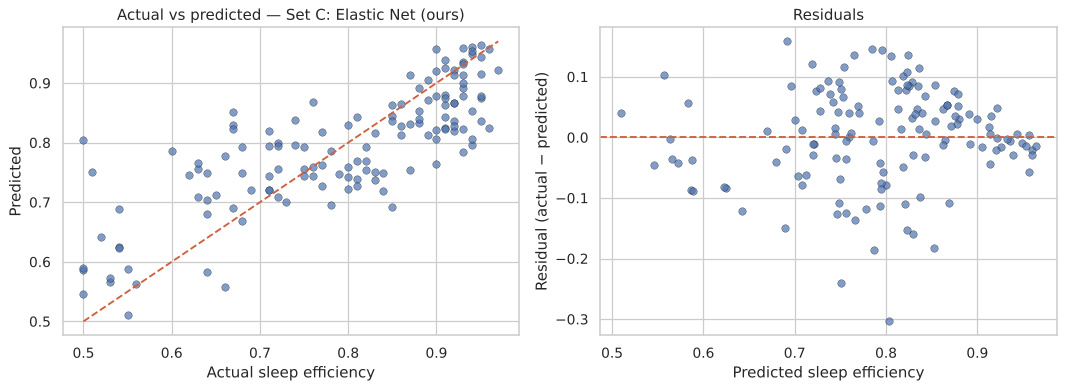

In [13]:
p_final = preds[final_label]
res = y_test.values - p_final

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, p_final, alpha=0.7, edgecolor="black", linewidth=0.3)
lo, hi = min(y_test.min(), p_final.min()), max(y_test.max(), p_final.max())
axes[0].plot([lo, hi], [lo, hi], "--", color="#d1603d")
axes[0].set_xlabel("Actual sleep efficiency"); axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Actual vs predicted — {final_label}")
axes[1].scatter(p_final, res, alpha=0.7, edgecolor="black", linewidth=0.3)
axes[1].axhline(0, ls="--", color="#d1603d")
axes[1].set_xlabel("Predicted sleep efficiency"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals")
fig.tight_layout(); fig.savefig(OUT_DIR / "04_actual_vs_pred_residuals.png", dpi=160); plt.show()

# Five largest absolute errors with their inputs (incl. the dropped sleep-stage columns for context)
err = pd.DataFrame({"actual": y_test, "predicted": p_final, "error": res}, index=y_test.index)
top = err.reindex(err["error"].abs().sort_values(ascending=False).index).head(5)
ctx = df_raw.loc[top.index, ["Age", "Gender", "Awakenings", "Alcohol consumption", "Smoking status",
                             "Exercise frequency", "Light sleep percentage"]]
print(top.join(ctx).round(3).to_string())

# The dropped Light-sleep % explains where the model fails (information not available to the model)
grp = np.where(df_raw.loc[y_test.index, "Light sleep percentage"] >= 40, "Light >= 40%", "Light < 40%")
by = pd.DataFrame({"abs_error": np.abs(res), "residual": res, "group": grp}).groupby("group") \
       .agg(n=("abs_error", "size"), MAE=("abs_error", "mean"), mean_residual=("residual", "mean"))
print("\nTest error by (dropped) light-sleep group:")
print(by.round(4).to_string())

## 14. Summary

In [14]:
best = main_df.set_index("Model").loc[final_label]
trivial = main_df.set_index("Model").loc["Trivial (mean)"]
setA = main_df.set_index("Model").loc["Set A: OLS (raw)"]
print(f"Final model          : {final_label}")
print(f"Features (Set C)     : {SET_C}")
print(f"CV MAE               : {best.CV_MAE:.4f} ± {best.CV_MAE_std:.4f}")
print(f"Test MAE / RMSE / R2 : {best.Test_MAE:.4f} / {best.Test_RMSE:.4f} / {best.Test_R2:.3f}")
print(f"vs Trivial test MAE  : {trivial.Test_MAE:.4f}  ({1 - best.Test_MAE / trivial.Test_MAE:.0%} lower)")
print(f"vs Set A test MAE    : {setA.Test_MAE:.4f}  ({1 - best.Test_MAE / setA.Test_MAE:.0%} lower)")
print(f"\nSaved to {OUT_DIR.resolve()} and {EDA_DIR.resolve()}")

Final model          : Set C: Elastic Net (ours)
Features (Set C)     : ['Age', 'Gender', 'Sleep duration', 'Bedtime_h', 'Caffeine consumption', 'Alcohol consumption', 'Smoking status', 'Exercise frequency', 'Awak_cap2', 'Age_sq', 'Alc_heavy', 'Ex_any', 'Smk_x_AlcHeavy']
CV MAE               : 0.0686 ± 0.0090
Test MAE / RMSE / R2 : 0.0630 / 0.0812 / 0.630
vs Trivial test MAE  : 0.1146  (45% lower)
vs Set A test MAE    : 0.0739  (15% lower)

Saved to /home/claude/nb/run/results and /home/claude/nb/run/eda_plots
